# Why the best of N backtests lies

**Author:** Franz Triebe · **Date:** 2026-10-11 · **Status:** final

**Question.** If you try N strategies that all have **zero true skill** and keep the best one, how good does the winner's backtest look? And can the probability of backtest overfitting (PBO) tell a real edge apart from lucky noise?

**Data.** Simulated daily returns only, so the true answer is known: normal returns and fat tailed Student t returns (5 degrees of freedom, rescaled to the same volatility). All random draws are seeded.

> **Key findings**
> 1. Keeping the best of **7** zero skill strategies gives an average annualized Sharpe ratio of **0.95** over a two year backtest (formula: 0.98). The best of 1,000 shows **2.31**. With ten years of data the same numbers are 0.43 and 1.02: longer samples shrink the luck, more tries inflate it.
> 2. The formula for the expected maximum is within **3.4%** of the simulation from N = 7 on, good enough to serve as the hurdle in the deflated Sharpe ratio. Fat tailed returns barely change the maximum.
> 3. PBO averages **0.47** for pure noise (single runs from 0.16 to 0.84), **0.02** when one strategy has a true Sharpe of 2.0, and **0.30** when it has a true Sharpe of 1.0. A real but moderate edge still competes with lucky noise.

**Contents**
1. [Setup](#1.-Setup)
2. [Simulation design](#2.-Simulation-design)
3. [Method](#3.-Method)
4. [Results](#4.-Results)
5. [Conclusions](#5.-Conclusions)
6. [Appendix: environment](#6.-Appendix:-environment)

## 1. Setup

In [1]:
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import quantlab
from IPython.display import display
from matplotlib.ticker import FixedLocator, NullLocator
from quantlab import acad, data, plotting, validation

In [2]:
N_GRID = [1, 2, 5, 7, 10, 20, 50, 100, 250, 1000]  # number of strategies tried
T_GRID = {504: "2 years", 2520: "10 years"}  # backtest length in trading days
N_SIMS = 2_000  # simulations per cell
T_DF = 5  # degrees of freedom of the fat tailed returns
SEED = 42  # base seed for every random draw
PBO_N, PBO_T, PBO_BLOCKS = 100, 2520, 16  # PBO calibration: trials, days, CSCV blocks
PBO_SEEDS = 20  # independent repetitions per PBO scenario
PBO_SCENARIOS = {
    "pure noise": 0.0,
    "one strategy with Sharpe 2.0": 2.0,
    "one strategy with Sharpe 1.0": 1.0,
}
ANN_FACTOR = 252  # trading days per year
RECOMPUTE = (
    False  # True reruns the simulations (about 2 minutes) instead of loading the cache
)
OUTPUT_DIR = Path(quantlab.__file__).resolve().parents[1] / "output" / "p01"

In [3]:
acad.apply_style()
pd.options.display.float_format = "{:,.4f}".format
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
NOTE_SIM = "Notes: simulated daily returns, every strategy with a true Sharpe ratio of 0, 2,000 simulations per point."

## 2. Simulation design

For each backtest length T and each return distribution we run the same experiment 2,000 times:

1. Draw 1,000 independent strategies of T daily returns, every one with a **true Sharpe ratio of exactly 0**.
2. Compute each strategy's sample Sharpe ratio $\widehat{SR} = \bar x / s_x$.
3. For every N in the grid, record the **best** Sharpe ratio among the first N strategies.

Reusing one draw of 1,000 strategies for all N is equivalent to separate experiments for each N, and it makes the curve over N smoother. The Sharpe ratio does not depend on the volatility level, so unit volatility returns are enough.

In [4]:
def run_or_load(path, compute):
    """Load a cached result if present, otherwise compute it and save it."""
    if path.exists() and not RECOMPUTE:
        return pd.read_csv(path)
    result = compute()
    result.to_csv(path, index=False)
    return result


def simulate_all():
    """Max daily Sharpe for every T, distribution and N; one row per simulation."""
    frames = []
    for i, (n_obs, dist) in enumerate(
        [(t, d) for t in T_GRID for d in ("normal", "t")]
    ):
        sim = validation.simulate_max_sr(
            n_obs, N_GRID, N_SIMS, dist=dist, df=T_DF, seed=SEED + i
        )
        frames.append(sim.assign(T=n_obs, dist=dist))
    return pd.concat(frames, ignore_index=True)


max_sr = run_or_load(OUTPUT_DIR / "mc_max_sharpe.csv", simulate_all)
max_sr.columns = [int(c) if c.isdigit() else c for c in max_sr.columns.astype(str)]
assert len(max_sr) == len(T_GRID) * 2 * N_SIMS and not max_sr.isna().any().any()
print(f"{len(max_sr):,} simulations loaded, {len(N_GRID)} values of N each")

8,000 simulations loaded, 10 values of N each


## 3. Method

**Expected maximum Sharpe ratio.** If each of N strategies has an estimated daily Sharpe ratio that is roughly normal with mean 0 and variance $V$, the expected best one is approximately (Bailey and Lopez de Prado 2014):

$$E\big[\max_N \widehat{SR}\big] \approx SR_0 = \sqrt{V}\Big((1-\gamma)\,\Phi^{-1}\big(1-\tfrac1N\big) + \gamma\,\Phi^{-1}\big(1-\tfrac{1}{Ne}\big)\Big)$$

where $\gamma \approx 0.5772$ is the Euler Mascheroni constant, $e$ is Euler's number and $\Phi^{-1}$ the standard normal quantile function. For a strategy with true Sharpe 0, the sampling variance of the daily Sharpe ratio is $V = 1/(T-1)$. This is order statistics: the expected maximum of N normal draws. It grows with N (more lottery tickets) and shrinks with T (each ticket is less noisy). We annualize with $\sqrt{252}$ only for display.

**Probability of backtest overfitting (PBO).** Combinatorially symmetric cross validation cuts the sample into $S = 16$ blocks and looks at all $\binom{16}{8} = 12{,}870$ ways to use half of them as in sample (IS) and the rest as out of sample (OOS). In each split we pick the best IS strategy and record its OOS rank $\omega \in (0, 1)$. PBO is the share of splits where the IS winner lands at or below the OOS median, $\omega \le 0.5$. For pure noise it should be about 0.5: picking the best backtest is then no better than picking at random.

In [5]:
def annualize(daily_sr):
    """Annualized Sharpe ratio for display; formulas always use daily values."""
    return daily_sr * np.sqrt(ANN_FACTOR)


def formula_curve(n_obs):
    """Expected max annualized Sharpe of N zero skill strategies, formula (c)."""
    return pd.Series(
        {n: annualize(validation.expected_max_sr(n, 1 / (n_obs - 1))) for n in N_GRID}
    )


check_value = formula_curve(504)[7]
print(f"Formula at N = 7, T = 504 (two years): annualized max Sharpe {check_value:.2f}")

Formula at N = 7, T = 504 (two years): annualized max Sharpe 0.98


## 4. Results

### 4.1 Best Sharpe ratio of N zero skill strategies

The table shows the average annualized Sharpe ratio of the winner, from simulation and from the formula, for both backtest lengths.

In [6]:
rows = []
for n_obs, label in T_GRID.items():
    for dist in ("normal", "t"):
        sims = annualize(
            max_sr.loc[(max_sr["T"] == n_obs) & (max_sr["dist"] == dist), N_GRID]
        )
        rows.append(sims.mean().rename((label, f"simulated, {dist}")))
    rows.append(formula_curve(n_obs).rename((label, "formula")))
table = pd.DataFrame(rows)
table.index = pd.MultiIndex.from_tuples(table.index, names=["backtest", "source"])
table.columns.name = "N strategies tried"
display(table.style.format("{:.2f}"))

**Reading the table.** With one strategy there is no selection, so the expected Sharpe is 0, as it should be. Every further try raises the winner's Sharpe ratio, quickly at first and then more slowly (roughly with the square root of the logarithm of N). The fat tailed rows are within 0.03 of the normal ones. The formula row tracks the simulation closely; Section 4.3 measures how closely.

### 4.2 Figure F1: the winner's Sharpe ratio grows with N and shrinks with T

The grey band holds 90% of the simulated winners (5th to 95th percentile) for normal returns; the lines show the averages and the formula.

In [7]:
def format_n_axis(ax):
    """Log x axis for the number of strategies, with readable integer ticks."""
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(FixedLocator([1, 2, 5, 10, 20, 50, 100, 250, 1000]))
    ax.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%d"))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlabel("Strategies tried, N (log scale)")

In [8]:
def draw_panel(ax, letter, n_obs, label):
    """One panel of F1: simulated band and means, plus the formula, against N."""
    sims = max_sr[max_sr["T"] == n_obs]
    normal = annualize(sims.loc[sims["dist"] == "normal", N_GRID])
    fat = annualize(sims.loc[sims["dist"] == "t", N_GRID])
    ax.fill_between(
        N_GRID,
        normal.quantile(0.05),
        normal.quantile(0.95),
        color=acad.LIGHT,
        alpha=0.6,
        linewidth=0,
        label="90% of simulations",
    )
    ax.plot(
        N_GRID,
        normal.mean(),
        color=acad.INK,
        linestyle="-",
        label="Simulated mean, normal",
    )
    ax.plot(
        N_GRID,
        fat.mean(),
        color=acad.INK,
        linestyle="--",
        label="Simulated mean, fat tails",
    )
    ax.plot(
        N_GRID,
        formula_curve(n_obs),
        color=acad.GREY,
        linestyle="-",
        marker="o",
        label="Formula",
    )
    format_n_axis(ax)
    acad.panel_title(ax, letter, f"T = {n_obs} days ({label})")

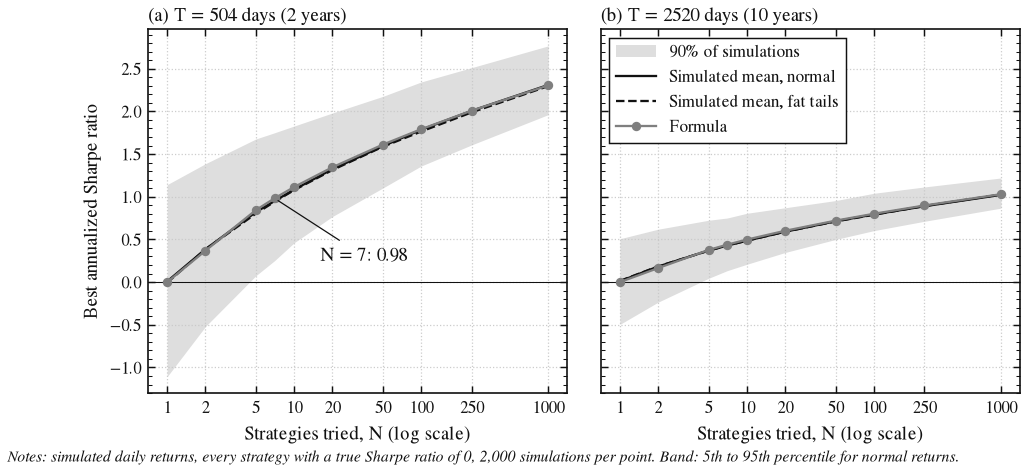

In [9]:
fig, axes = acad.new_fig(
    "wide", aspect=0.42, ncols=2, sharey=True, gridspec_kw={"wspace": 0.08}
)
for ax, letter, (n_obs, label) in zip(axes, "ab", T_GRID.items(), strict=True):
    draw_panel(ax, letter, n_obs, label)
acad.zero_line(axes[0])
acad.zero_line(axes[1])
axes[0].set_ylabel("Best annualized Sharpe ratio")
seven = formula_curve(504)[7]
axes[0].annotate(
    f"N = 7: {seven:.2f}",
    (7, seven),
    xytext=(22, -30),
    textcoords="offset points",
    arrowprops={"arrowstyle": "-", "color": acad.INK, "linewidth": 0.6},
)
axes[1].legend(loc="upper left")
acad.source_note(fig, NOTE_SIM + " Band: 5th to 95th percentile for normal returns.")
acad.save(fig, "f1_max_sharpe", outdir=OUTPUT_DIR)
plt.show()

**Figure 1.** Seven tries at zero skill already produce a Sharpe ratio near 1 over two years, and ten years of data cut that luck by about half.

**Reading the chart.** Read panel (a) from left to right: one strategy has an expected Sharpe of 0, but the best of 7 already shows about 1, and the best of 1,000 about 2.3, all without any skill. Panel (b) has the same shape at a lower level: ten years of data shrink the luck by a factor of about $\sqrt{5} \approx 2.2$. The dashed fat tail line lies almost on top of the normal one, so for the maximum it is mostly N and T that matter. Fat tails matter more for the precision of a single Sharpe ratio, which PSR and DSR account for.

### 4.3 How accurate is the formula?

The relative error of the formula against the simulated mean, for normal returns.

In [10]:
errors = {}
for n_obs, label in T_GRID.items():
    sims = annualize(
        max_sr.loc[(max_sr["T"] == n_obs) & (max_sr["dist"] == "normal"), N_GRID]
    ).mean()
    errors[label] = (formula_curve(n_obs) / sims - 1).drop(1)
error_table = pd.DataFrame(errors).T
error_table.columns.name = "N strategies tried"
display(error_table.style.format("{:+.1%}"))

N strategies tried,2,5,7,10,20,50,100,250,1000
2 years,-4.4%,+2.8%,+3.4%,+2.7%,+1.7%,+1.2%,+0.3%,+0.1%,-0.2%
10 years,-9.9%,+2.0%,+2.6%,+2.5%,+1.9%,+1.0%,+1.0%,+1.0%,+0.8%


**Reading the table.** For N of 7 and more the formula is within 3.4% of the simulation, close enough to serve as the hurdle in the deflated Sharpe ratio; PLAN.md expected about 4%. For N = 2 it is 4% too low with two years of data and 10% too low with ten, because an extreme value approximation needs more than two draws. PLAN.md expected 9% to 13% here, which matches the ten year case.

### 4.4 PBO calibration: noise, a strong edge and a moderate edge

We run CSCV on {PBO_N} trials of {PBO_T} days in three scenarios, each repeated with 20 different seeds, because a single PBO estimate scatters a lot.

In [11]:
def pbo_runs(planted_sharpe):
    """PBO for one scenario over PBO_SEEDS seeds: trial 0 has the planted Sharpe, the rest 0."""
    sharpes = np.zeros(PBO_N)
    sharpes[0] = planted_sharpe
    values = []
    for k in range(PBO_SEEDS):
        trials = data.simulate_returns(
            PBO_T, n_assets=PBO_N, ann_sharpe=sharpes, seed=SEED + 1_000 + k
        )
        values.append(validation.pbo_cscv(trials, n_blocks=PBO_BLOCKS)["pbo"])
    return pd.Series(values)


pbo = pd.DataFrame({name: pbo_runs(sr) for name, sr in PBO_SCENARIOS.items()})
pbo_summary = pbo.describe(percentiles=[0.5]).T[["mean", "50%", "min", "max"]]
pbo_summary.columns = ["mean", "median", "lowest", "highest"]
display(pbo_summary.style.format("{:.2f}"))

,mean,median,lowest,highest
pure noise,0.47,0.47,0.16,0.84
one strategy with Sharpe 2.0,0.02,0.00,0.00,0.15
one strategy with Sharpe 1.0,0.30,0.27,0.01,0.64


In [12]:
def draw_pbo_dots(ax):
    """One row per scenario: a dot per simulated history and a bar at the mean."""
    for i, name in enumerate(PBO_SCENARIOS):
        jitter = np.random.default_rng(SEED + i).uniform(-0.12, 0.12, PBO_SEEDS)
        ax.scatter(pbo[name], i + jitter, color=acad.GREY, s=12, linewidth=0)
        ax.plot(
            [pbo[name].mean()] * 2,
            [i - 0.25, i + 0.25],
            color=acad.INK,
            linestyle="-",
            linewidth=1.6,
        )
    ax.set_yticks(
        range(len(PBO_SCENARIOS)),
        ["Pure noise", "One strategy with Sharpe 2.0", "One strategy with Sharpe 1.0"],
    )
    ax.tick_params(axis="y", which="both", length=0)
    ax.yaxis.set_minor_locator(NullLocator())
    ax.set_ylim(len(PBO_SCENARIOS) - 0.5, -0.5)

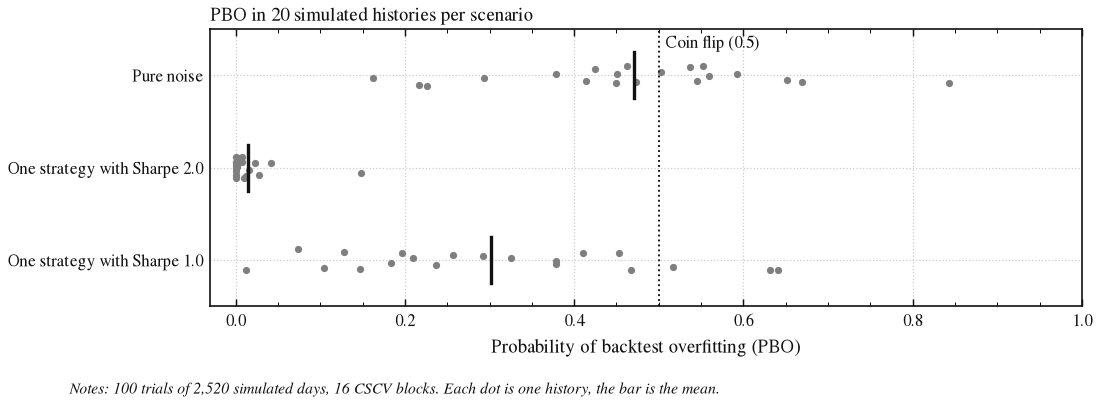

In [13]:
fig, ax = acad.new_fig("wide", aspect=0.32)
draw_pbo_dots(ax)
plotting.reference_line(ax, 0.5, "Coin flip (0.5)", axis="x", linestyle=":")
ax.set_xlim(-0.03, 1)
ax.set_xlabel("Probability of backtest overfitting (PBO)")
ax.set_title("PBO in 20 simulated histories per scenario")
acad.source_note(
    fig,
    "Notes: 100 trials of 2,520 simulated days, 16 CSCV blocks. Each dot is one history, the bar is the mean.",
    y=-0.1,
)
acad.save(fig, "f1b_pbo_calibration", outdir=OUTPUT_DIR)
plt.show()

**Figure 2.** PBO sits near 0.5 for noise and near 0 for a strong edge; a moderate edge lands in between.

**Reading the chart.** For pure noise the dots spread around 0.5, the coin flip level, but a single run can land anywhere from 0.16 to 0.84. Never trust one PBO draw on its own. A strategy with a true Sharpe of 2.0 is found almost every time (mean 0.02). A true Sharpe of 1.0 is the interesting case: the mean is 0.30, and in 3 of 20 runs PBO is above 0.5. The real edge is there, but over ten years of data a few of the 99 noise strategies look just as good in sample. PLAN.md expected about 0.25 for this case; with 20 seeds we measure 0.30, within the scatter.

## 5. Conclusions

1. **The best of N lies, and predictably so.** Seven tries at zero skill already produce a Sharpe ratio near 1 over two years. Any backtest result has to be compared with the best of the N tries that produced it, not with 0. This is the job of the deflated Sharpe ratio in `quantlab.validation`.
2. **The hurdle formula works.** It is within 3.4% of the simulation for N of 7 or more and is only clearly off for N = 2 (4% to 10% too low), where it matters least.
3. **PBO separates noise from a strong edge, but not reliably from a moderate one.** Its mean behaves as expected (0.47, 0.02, 0.30), while single estimates scatter widely. In the referee it is therefore one input next to the DSR, never the only one.

> **Caveats:** all trials here are independent. Real trial families (Phase 3) are highly correlated, which lowers the effective number of trials and the hurdle. The simulation also ignores autocorrelation and volatility clustering, which real returns show (see notebook 01).

**Next step:** Phase 3 builds the 256 trend timing trials on SPY, tests them for look ahead bias, and ranks them, before the referee sees them.

## 6. Appendix: environment

In [14]:
versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "quantlab": version("quantlab"),
}
print(", ".join(f"{k} {v}" for k, v in versions.items()))

python 3.12.11, numpy 2.5.4, pandas 3.0.6, matplotlib 3.11.2, quantlab 0.1.0
